# ЛР1: анализ распределения SMS Spam Collection

Направление NLP: классификация SMS как ham/spam для сервиса фильтрации. Источник — UCI, исходный размер 5572 сообщения, два класса. Проверяется исходный SHA256 и отдельная очистка для обучения.

In [1]:
from pathlib import Path
import sys, json
root = Path.cwd()
if root.name == 'notebooks':
    root = root.parent
sys.path.insert(0, str(root))
from src.data_utils import load_and_check
df, info = load_and_check()
print(json.dumps(info, ensure_ascii=False, indent=2))


{
  "dataset_path": "data/SMSSpamCollection",
  "dataset_sha256": "7d039a24a6083ed9ef0f806ebad56bbb976e3aeb8de05669173bfdc4996c239d",
  "reference": "data/dataset.sha256",
  "original_rows": 5572,
  "duplicates_removed": 415,
  "conflicting_label_rows_removed": 0,
  "remaining_rows": 5157,
  "class_counts": {
    "ham": 4515,
    "spam": 642
  },
  "missing_values": 0,
  "empty_messages": 0,
  "label_values": [
    "ham",
    "spam"
  ],
  "feature_types": {
    "message": "string",
    "label": "string"
  }
}


label
ham     4825
spam     747
Name: count, dtype: int64
label
ham     86.59
spam    13.41
Name: count, dtype: float64


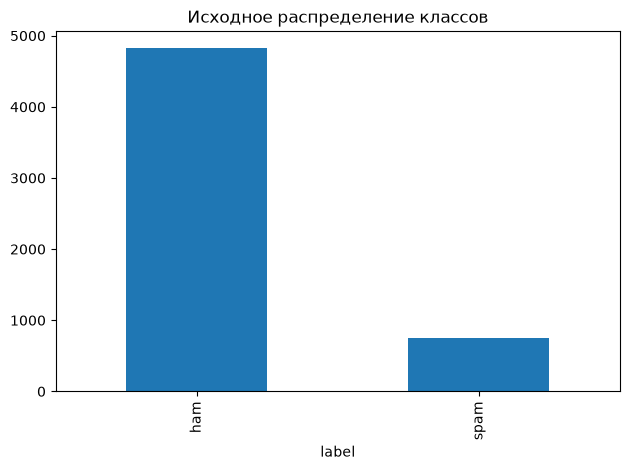

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
raw = pd.read_csv(root/'data/SMSSpamCollection', sep='\t', header=None, names=['label','message'])
counts = raw.label.value_counts()
print(counts)
print((counts / counts.sum() * 100).round(2))
counts.plot.bar(title='Исходное распределение классов')
plt.tight_layout()
plt.show()


## Вывод

В исходном наборе 4825 ham (86.59%) и 747 spam (13.41%); обычных сообщений примерно в 6.5 раза больше. Accuracy большинства была бы высокой даже без выявления spam. Для обучения используются стратификация и class_weight=balanced, для оценки — Precision/Recall/F1 spam и метрики по обоим классам. Искусственное изменение тестового распределения не выполняется. После удаления нормализованных дублей остаются 4515 ham и 642 spam. Оба класса представлены в train/test, но исторический английский набор, небольшое число spam и отсутствие групповых идентификаторов ограничивают выводы о применимости.